# Data Preprocessing

In [3]:
import numpy as np 
import pandas as pd 

df=pd.read_csv("Renewable.csv");
print(df.shape);
print(df.head());

(196776, 17)
               Time  Energy  GHI  temp  pressure  humidity  wind_speed  \
0  01-01-2017 00:00       0  0.0   1.6      1021       100         4.9   
1  01-01-2017 00:15       0  0.0   1.6      1021       100         4.9   
2  01-01-2017 00:30       0  0.0   1.6      1021       100         4.9   
3  01-01-2017 00:45       0  0.0   1.6      1021       100         4.9   
4  01-01-2017 01:00       0  0.0   1.7      1020       100         5.2   

   rain_1h  snow_1h  clouds_all  isSun  sunlightTime  dayLength  \
0      0.0      0.0         100      0             0        450   
1      0.0      0.0         100      0             0        450   
2      0.0      0.0         100      0             0        450   
3      0.0      0.0         100      0             0        450   
4      0.0      0.0         100      0             0        450   

   SunlightTime/daylength  weather_type  hour  month  
0                     0.0             4     0      1  
1                     0.0    

In [4]:
print(df.duplicated().sum());
print(df.isnull().sum());

0
Time                      0
Energy                    0
GHI                       0
temp                      0
pressure                  0
humidity                  0
wind_speed                0
rain_1h                   0
snow_1h                   0
clouds_all                0
isSun                     0
sunlightTime              0
dayLength                 0
SunlightTime/daylength    0
weather_type              0
hour                      0
month                     0
dtype: int64


In [5]:
df["Time"] = pd.to_datetime(df["Time"],format="%d-%m-%Y %H:%M")
df = df.sort_values("Time").reset_index(drop=True)

In [6]:
print(df["Time"].head())
print(df["Time"].dtype)

0   2017-01-01 00:00:00
1   2017-01-01 00:15:00
2   2017-01-01 00:30:00
3   2017-01-01 00:45:00
4   2017-01-01 01:00:00
Name: Time, dtype: datetime64[ns]
datetime64[ns]


In [7]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check duplicate timestamps
print("Duplicate timestamps:", df["Time"].duplicated().sum())

Missing values:
Time                      0
Energy                    0
GHI                       0
temp                      0
pressure                  0
humidity                  0
wind_speed                0
rain_1h                   0
snow_1h                   0
clouds_all                0
isSun                     0
sunlightTime              0
dayLength                 0
SunlightTime/daylength    0
weather_type              0
hour                      0
month                     0
dtype: int64

Duplicate rows: 0
Duplicate timestamps: 0


In [8]:
columns_to_drop = [
    "isSun",
    "sunlightTime",
    "dayLength",
    "SunlightTime/daylength",
    "hour",
    "month",
    "snow_1h"
]

df.drop(columns=columns_to_drop, inplace=True)

In [9]:
print(df.columns.tolist())

['Time', 'Energy', 'GHI', 'temp', 'pressure', 'humidity', 'wind_speed', 'rain_1h', 'clouds_all', 'weather_type']


In [10]:
# Convert interval energy into average power in Watts
df["Power_W"] = df["Energy"] * 4

# Display the result
print(df[["Energy", "Power_W"]].head())

   Energy  Power_W
0       0        0
1       0        0
2       0        0
3       0        0
4       0        0


In [11]:
df["hour"] = df["Time"].dt.hour

df["day_of_year"] = df["Time"].dt.dayofyear

df["day_of_week"] = df["Time"].dt.dayofweek

df["month"] = df["Time"].dt.month

print(df[["Time", "hour", "month", "day_of_year","day_of_week"]].head(10))

                 Time  hour  month  day_of_year  day_of_week
0 2017-01-01 00:00:00     0      1            1            6
1 2017-01-01 00:15:00     0      1            1            6
2 2017-01-01 00:30:00     0      1            1            6
3 2017-01-01 00:45:00     0      1            1            6
4 2017-01-01 01:00:00     1      1            1            6
5 2017-01-01 01:15:00     1      1            1            6
6 2017-01-01 01:30:00     1      1            1            6
7 2017-01-01 01:45:00     1      1            1            6
8 2017-01-01 02:00:00     2      1            1            6
9 2017-01-01 02:15:00     2      1            1            6


In [12]:
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)

df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df["day_of_year_sin"] = np.sin(
    2 * np.pi * df["day_of_year"] / 365.25
)

df["day_of_year_cos"] = np.cos(
    2 * np.pi * df["day_of_year"] / 365.25
)

In [13]:
df.drop(columns=["Energy"], inplace=True)

In [14]:
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

                 Time  GHI  temp  pressure  humidity  wind_speed  rain_1h  \
0 2017-01-01 00:00:00  0.0   1.6      1021       100         4.9      0.0   
1 2017-01-01 00:15:00  0.0   1.6      1021       100         4.9      0.0   
2 2017-01-01 00:30:00  0.0   1.6      1021       100         4.9      0.0   
3 2017-01-01 00:45:00  0.0   1.6      1021       100         4.9      0.0   
4 2017-01-01 01:00:00  0.0   1.7      1020       100         5.2      0.0   

   clouds_all  weather_type  Power_W  hour  day_of_year  day_of_week  month  \
0         100             4        0     0            1            6      1   
1         100             4        0     0            1            6      1   
2         100             4        0     0            1            6      1   
3         100             4        0     0            1            6      1   
4         100             4        0     1            1            6      1   

   hour_sin  hour_cos  day_of_year_sin  day_of_year_cos  
0  0

# Exploratory Data Analysis (Analyzing Data)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 196776 entries, 0 to 196775
Data columns (total 18 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   Time             196776 non-null  datetime64[ns]
 1   GHI              196776 non-null  float64       
 2   temp             196776 non-null  float64       
 3   pressure         196776 non-null  int64         
 4   humidity         196776 non-null  int64         
 5   wind_speed       196776 non-null  float64       
 6   rain_1h          196776 non-null  float64       
 7   clouds_all       196776 non-null  int64         
 8   weather_type     196776 non-null  int64         
 9   Power_W          196776 non-null  int64         
 10  hour             196776 non-null  int32         
 11  day_of_year      196776 non-null  int32         
 12  day_of_week      196776 non-null  int32         
 13  month            196776 non-null  int32         
 14  hour_sin         196

In [16]:
# Display statistical summary
df.describe()

,Time,GHI,temp,pressure,humidity,wind_speed,rain_1h,clouds_all,weather_type,Power_W,hour,day_of_year,day_of_week,month,hour_sin,hour_cos,day_of_year_sin,day_of_year_cos
count,196776,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000,1.967760e+05,1.967760e+05,196776.000000,196776.000000
mean,2019-10-29 22:44:12.085620992,32.596538,9.790521,1015.292780,79.810566,3.937746,0.066035,65.974387,3.198398,2292.032911,11.498902,176.222100,2.992804,6.298329,8.736588e-05,-6.703820e-05,0.042480,-0.032044
min,2017-01-01 00:00:00,0.000000,-16.600000,977.000000,22.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000,-1.000000e+00,-1.000000e+00,-0.999999,-0.999979
25%,2018-06-02 10:26:15,0.000000,3.600000,1010.000000,70.000000,2.600000,0.000000,34.000000,2.000000,0.000000,5.000000,88.000000,1.000000,3.000000,-7.071068e-01,-7.071068e-01,-0.653160,-0.743001
50%,2019-10-28 20:52:30,1.600000,9.300000,1016.000000,84.000000,3.700000,0.000000,82.000000,4.000000,0.000000,11.000000,173.000000,3.000000,6.000000,1.224647e-16,-1.836970e-16,0.085906,-0.063391
75%,2021-03-24 07:18:45,46.800000,15.700000,1021.000000,92.000000,5.000000,0.000000,100.000000,4.000000,2308.000000,17.000000,262.000000,5.000000,9.000000,7.071068e-01,7.071068e-01,0.742281,0.678031
max,2022-08-31 17:45:00,229.200000,35.800000,1047.000000,100.000000,14.300000,8.090000,100.000000,5.000000,20080.000000,23.000000,366.000000,6.000000,12.000000,1.000000e+00,1.000000e+00,0.999986,0.999991
std,NaN,52.172018,7.995428,9.585773,15.604459,1.821694,0.278913,36.628593,1.289939,4179.296186,6.921887,103.218601,2.001181,3.376066,7.071014e-01,7.071158e-01,0.703553,0.708651


In [17]:
print("Average Power:", df["Power_W"].mean())

print("Maximum Power:", df["Power_W"].max())

print("Minimum Power:", df["Power_W"].min())

print("Standard Deviation:", df["Power_W"].std())

Average Power: 2292.032910517543
Maximum Power: 20080
Minimum Power: 0
Standard Deviation: 4179.296186161317


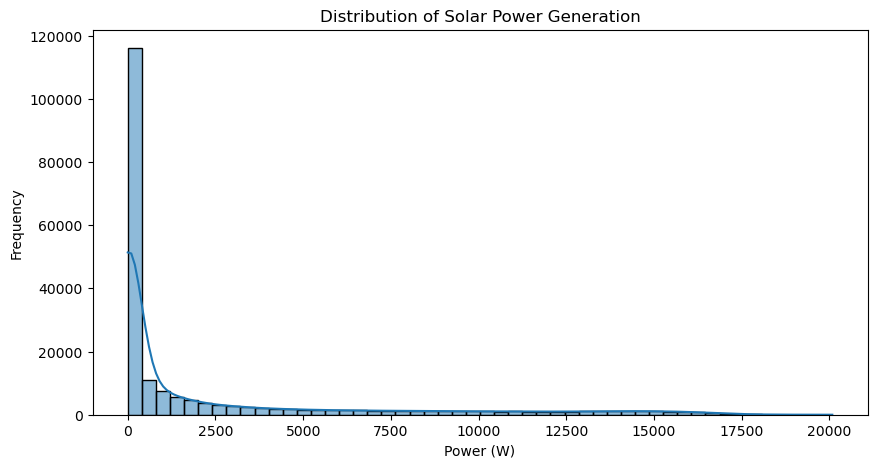

In [18]:
# Distribution of Power_W
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(df["Power_W"], bins=50, kde=True)

plt.title("Distribution of Solar Power Generation")
plt.xlabel("Power (W)")
plt.ylabel("Frequency")

plt.show()

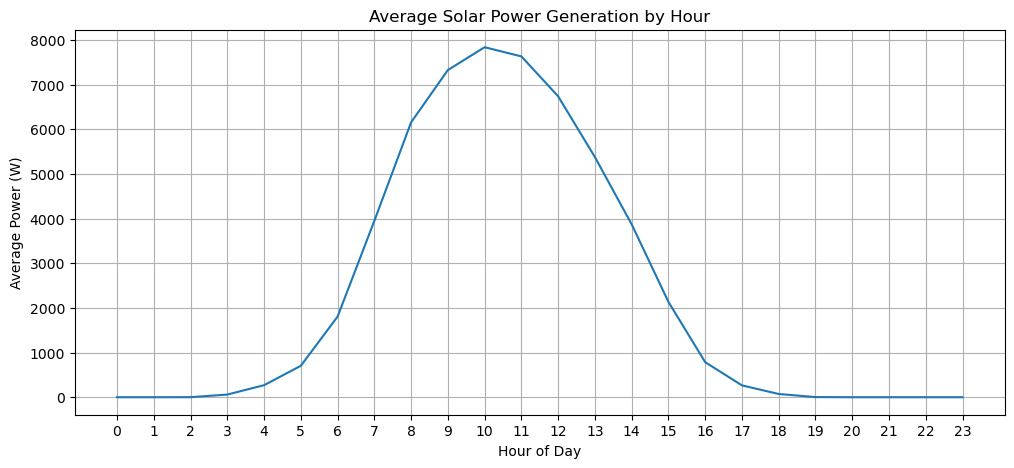

In [19]:
# Average Power_W for each hour
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=df,
    x="hour",
    y="Power_W",
    estimator="mean",
    errorbar=None
)

plt.title("Average Solar Power Generation by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Power (W)")

plt.xticks(range(0, 24))
plt.grid(True)

plt.show()

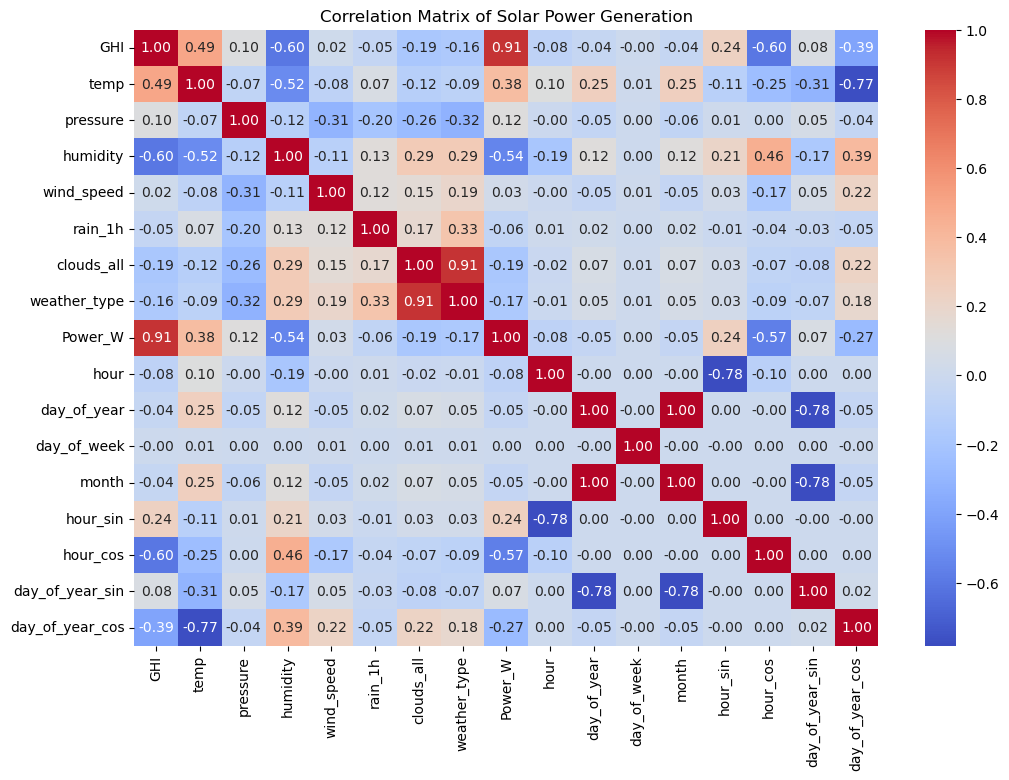

In [20]:
# Which environmental features have a strong relationship with solar power generation

# | Correlation | Interpretation |
# | +1.00 | Perfect positive relationship |
# | +0.70 | Strong positive relationship |
# | +0.00 | No linear relationship |
# | -0.70 | Strong negative relationship |
# | -1.00 | Perfect negative relationship |

# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlation
correlation_matrix = numeric_df.corr()

# Visualize correlation
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Solar Power Generation")

plt.show()

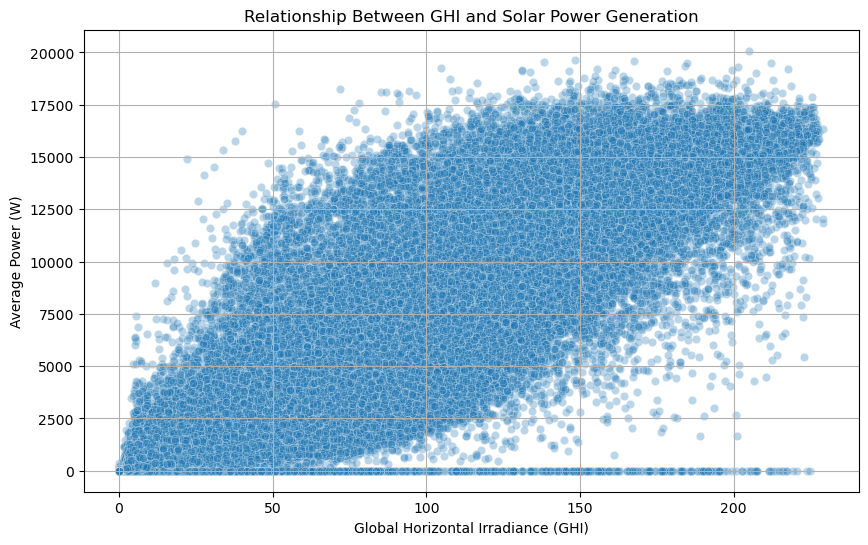

In [21]:
# visualizing the strongest relationship (GHI)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="GHI",
    y="Power_W",
    alpha=0.3
)

plt.title("Relationship Between GHI and Solar Power Generation")
plt.xlabel("Global Horizontal Irradiance (GHI)")
plt.ylabel("Average Power (W)")

plt.grid(True)

plt.show()



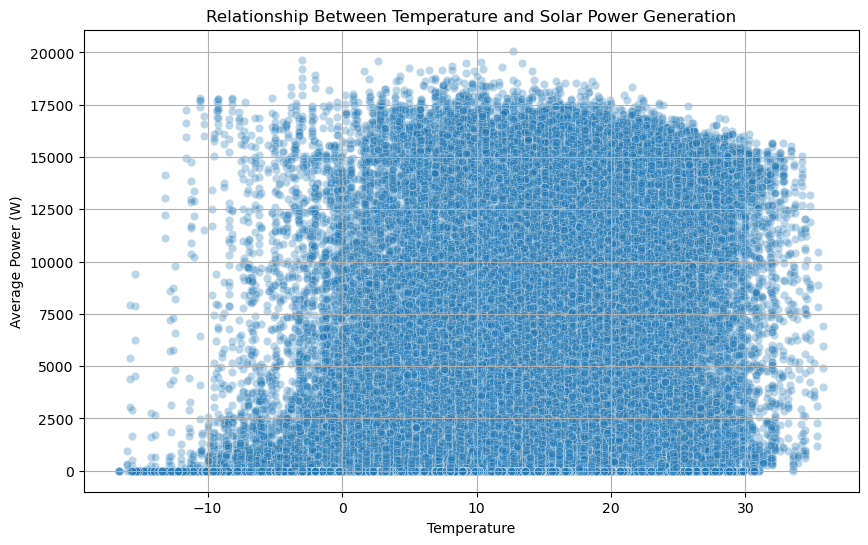

In [22]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="temp",
    y="Power_W",
    alpha=0.3
)

plt.title("Relationship Between Temperature and Solar Power Generation")
plt.xlabel("Temperature")
plt.ylabel("Average Power (W)")

plt.grid(True)

plt.show()

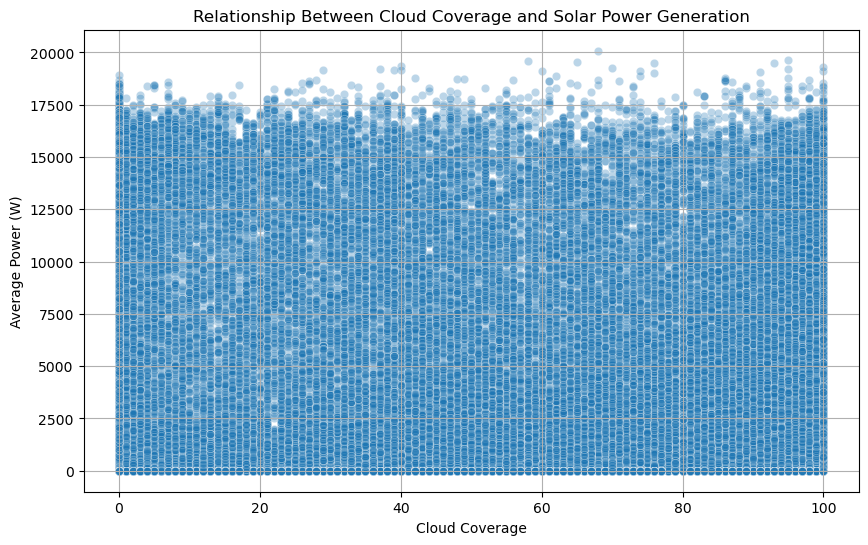

In [23]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="clouds_all",
    y="Power_W",
    alpha=0.3
)

plt.title("Relationship Between Cloud Coverage and Solar Power Generation")
plt.xlabel("Cloud Coverage")
plt.ylabel("Average Power (W)")

plt.grid(True)

plt.show()

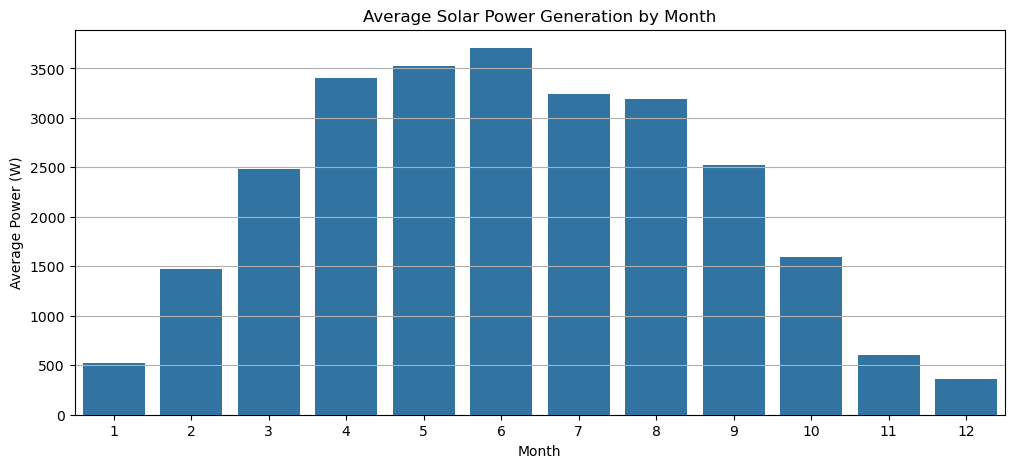

In [24]:
# Average power by month

plt.figure(figsize=(12, 5))

sns.barplot(
    data=df,
    x="month",
    y="Power_W",
    estimator="mean",
    errorbar=None
)

plt.title("Average Solar Power Generation by Month")
plt.xlabel("Month")
plt.ylabel("Average Power (W)")

plt.grid(axis="y")

plt.show()

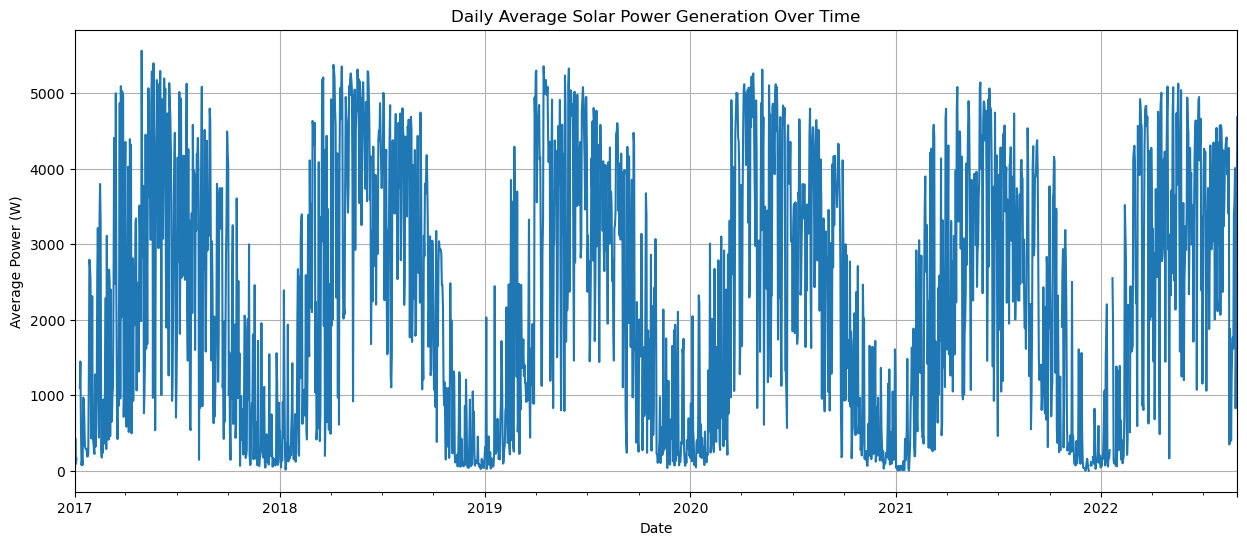

In [25]:
# Set Time as the index
daily_power = df.set_index("Time")["Power_W"].resample("D").mean()

# Plot daily average power
plt.figure(figsize=(15, 6))

daily_power.plot()

plt.title("Daily Average Solar Power Generation Over Time")
plt.xlabel("Date")
plt.ylabel("Average Power (W)")

plt.grid(True)

plt.show()

In [26]:
print(df["weather_type"].unique())

print("\nNumber of weather categories:")
print(df["weather_type"].nunique())

[4 5 3 2 1]

Number of weather categories:
5


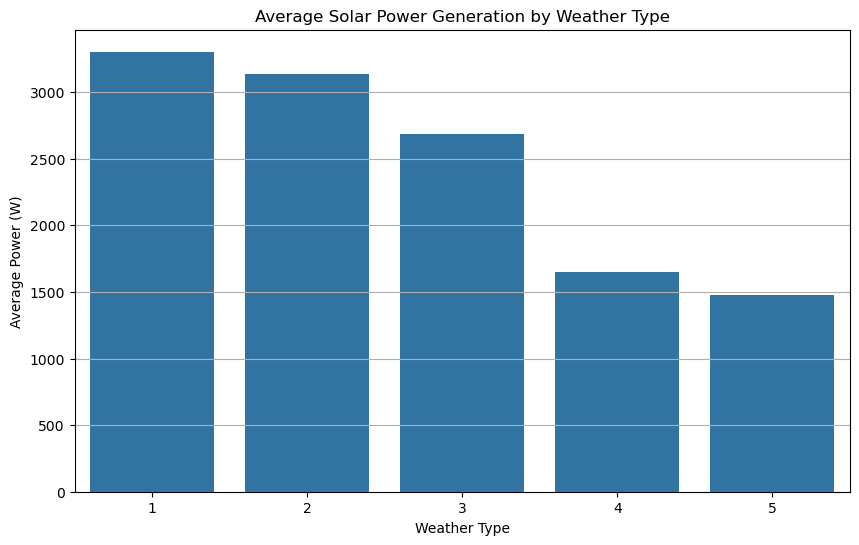

In [27]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="weather_type",
    y="Power_W",
    estimator="mean",
    errorbar=None
)

plt.title("Average Solar Power Generation by Weather Type")
plt.xlabel("Weather Type")
plt.ylabel("Average Power (W)")

plt.grid(axis="y")

plt.show()

##### df.groupby("weather_type")["Power_W"].agg(
    ["count", "mean", "median", "min", "max"]
)

In [29]:
# EDA SUMMARY

print("Total observations:", len(df))

print("\nPower Statistics:")
print(df["Power_W"].describe())

print("\nZero Power Observations:")
print((df["Power_W"] == 0).sum())

print("\nNegative Power Observations:")
print((df["Power_W"] < 0).sum())

Total observations: 196776

Power Statistics:
count    196776.000000
mean       2292.032911
std        4179.296186
min           0.000000
25%           0.000000
50%           0.000000
75%        2308.000000
max       20080.000000
Name: Power_W, dtype: float64

Zero Power Observations:
100850

Negative Power Observations:
0


# Feature Engineering & Model Preparation

In [30]:
df.columns

Index(['Time', 'GHI', 'temp', 'pressure', 'humidity', 'wind_speed', 'rain_1h',
       'clouds_all', 'weather_type', 'Power_W', 'hour', 'day_of_year',
       'day_of_week', 'month', 'hour_sin', 'hour_cos', 'day_of_year_sin',
       'day_of_year_cos'],
      dtype='object')

In [31]:
df.head()

,Time,GHI,temp,pressure,humidity,wind_speed,rain_1h,clouds_all,weather_type,Power_W,hour,day_of_year,day_of_week,month,hour_sin,hour_cos,day_of_year_sin,day_of_year_cos
0,2017-01-01 00:00:00,0.0,1.6,1021,100,4.9,0.0,100,4,0,0,1,6,1,0.000000,1.000000,0.017202,0.999852
1,2017-01-01 00:15:00,0.0,1.6,1021,100,4.9,0.0,100,4,0,0,1,6,1,0.000000,1.000000,0.017202,0.999852
2,2017-01-01 00:30:00,0.0,1.6,1021,100,4.9,0.0,100,4,0,0,1,6,1,0.000000,1.000000,0.017202,0.999852
3,2017-01-01 00:45:00,0.0,1.6,1021,100,4.9,0.0,100,4,0,0,1,6,1,0.000000,1.000000,0.017202,0.999852
4,2017-01-01 01:00:00,0.0,1.7,1020,100,5.2,0.0,100,4,0,1,1,6,1,0.258819,0.965926,0.017202,0.999852


In [32]:
# select input features

# Select input features
X = df[
    [
        "GHI",
        "temp",
        "pressure",
        "humidity",
        "wind_speed",
        "rain_1h",
        "clouds_all",
        "weather_type",
        "hour_sin",
        "hour_cos",
        "day_of_year_sin",
        "day_of_year_cos",
        "day_of_week"
    ]
]

# Select target variable
y = df["Power_W"]

# Preserve timestamps for chronological splitting and analysis
timestamps = df["Time"]

# Check shapes
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Timestamps shape:", timestamps.shape)

# Preview
X.head()

X shape: (196776, 13)
y shape: (196776,)
Timestamps shape: (196776,)


,GHI,temp,pressure,humidity,wind_speed,rain_1h,clouds_all,weather_type,hour_sin,hour_cos,day_of_year_sin,day_of_year_cos,day_of_week
0,0.0,1.6,1021,100,4.9,0.0,100,4,0.000000,1.000000,0.017202,0.999852,6
1,0.0,1.6,1021,100,4.9,0.0,100,4,0.000000,1.000000,0.017202,0.999852,6
2,0.0,1.6,1021,100,4.9,0.0,100,4,0.000000,1.000000,0.017202,0.999852,6
3,0.0,1.6,1021,100,4.9,0.0,100,4,0.000000,1.000000,0.017202,0.999852,6
4,0.0,1.7,1020,100,5.2,0.0,100,4,0.258819,0.965926,0.017202,0.999852,6


In [33]:
print(X["weather_type"].value_counts().sort_index())

weather_type
1    27976
2    35428
3    31660
4    73004
5    28708
Name: count, dtype: int64


In [34]:
# One-Hot Encode weather_type
X_encoded = pd.get_dummies(
    X,
    columns=["weather_type"],
    dtype=int
)

# Check the result
print("Original X shape:", X.shape)
print("Encoded X shape:", X_encoded.shape)

print("\nNew columns:")
print(X_encoded.columns.tolist())

X_encoded.head()

Original X shape: (196776, 13)
Encoded X shape: (196776, 17)

New columns:
['GHI', 'temp', 'pressure', 'humidity', 'wind_speed', 'rain_1h', 'clouds_all', 'hour_sin', 'hour_cos', 'day_of_year_sin', 'day_of_year_cos', 'day_of_week', 'weather_type_1', 'weather_type_2', 'weather_type_3', 'weather_type_4', 'weather_type_5']


,GHI,temp,pressure,humidity,wind_speed,rain_1h,clouds_all,hour_sin,hour_cos,day_of_year_sin,day_of_year_cos,day_of_week,weather_type_1,weather_type_2,weather_type_3,weather_type_4,weather_type_5
0,0.0,1.6,1021,100,4.9,0.0,100,0.000000,1.000000,0.017202,0.999852,6,0,0,0,1,0
1,0.0,1.6,1021,100,4.9,0.0,100,0.000000,1.000000,0.017202,0.999852,6,0,0,0,1,0
2,0.0,1.6,1021,100,4.9,0.0,100,0.000000,1.000000,0.017202,0.999852,6,0,0,0,1,0
3,0.0,1.6,1021,100,4.9,0.0,100,0.000000,1.000000,0.017202,0.999852,6,0,0,0,1,0
4,0.0,1.7,1020,100,5.2,0.0,100,0.258819,0.965926,0.017202,0.999852,6,0,0,0,1,0


# Chronological Train-Test-split

In [35]:
from sklearn.preprocessing import StandardScaler

# Calculate split index
split_index = int(len(X_encoded) * 0.80)

# Split input features
X_train = X_encoded.iloc[:split_index]
X_test = X_encoded.iloc[split_index:]

# Split target variable
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Preserve timestamps
time_train = timestamps.iloc[:split_index]
time_test = timestamps.iloc[split_index:]

# Display dataset shapes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

# Display date ranges
print("\nTraining Period:")
print(time_train.min(), "to", time_train.max())

print("\nTesting Period:")
print(time_test.min(), "to", time_test.max())

Training Features: (157420, 17)
Testing Features: (39356, 17)
Training Target: (157420,)
Testing Target: (39356,)

Training Period:
2017-01-01 00:00:00 to 2021-07-04 18:45:00

Testing Period:
2021-07-04 19:00:00 to 2022-08-31 17:45:00


In [36]:
# Feature scaling
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using training statistics
X_test_scaled = scaler.transform(X_test)

# Check shapes
print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

# Check scaled feature values
print("\nFirst 5 scaled observations:")
print(X_train_scaled[:5])

Scaled Training Shape: (157420, 17)
Scaled Testing Shape: (39356, 17)

First 5 scaled observations:
[[-6.16856371e-01 -9.86951204e-01  6.21936484e-01  1.29240453e+00
   5.29407566e-01 -2.40654645e-01  9.30492898e-01 -1.18508512e-04
   1.41433208e+00 -7.54386142e-02  1.42174822e+00  1.50156894e+00
  -4.15290484e-01 -4.68202659e-01 -4.31772977e-01  1.31218678e+00
  -4.17726756e-01]
 [-6.16856371e-01 -9.86951204e-01  6.21936484e-01  1.29240453e+00
   5.29407566e-01 -2.40654645e-01  9.30492898e-01 -1.18508512e-04
   1.41433208e+00 -7.54386142e-02  1.42174822e+00  1.50156894e+00
  -4.15290484e-01 -4.68202659e-01 -4.31772977e-01  1.31218678e+00
  -4.17726756e-01]
 [-6.16856371e-01 -9.86951204e-01  6.21936484e-01  1.29240453e+00
   5.29407566e-01 -2.40654645e-01  9.30492898e-01 -1.18508512e-04
   1.41433208e+00 -7.54386142e-02  1.42174822e+00  1.50156894e+00
  -4.15290484e-01 -4.68202659e-01 -4.31772977e-01  1.31218678e+00
  -4.17726756e-01]
 [-6.16856371e-01 -9.86951204e-01  6.21936484e-01  

# Model Training and Evaluation

In [37]:
from sklearn.linear_model import LinearRegression

# Create Linear Regression model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train_scaled, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [38]:
y_pred_lr = lr_model.predict(X_test_scaled)

print("Predictions generated successfully!")
print(y_pred_lr[:10])

Predictions generated successfully!
[-694.02206814 -861.94423554 -884.84271291 -884.84271291 -878.4152583
 -878.4152583  -878.4152583  -878.4152583  -869.40087543 -869.40087543]


In [40]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_lr)
mse = mean_squared_error(y_test, y_pred_lr)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_lr)

print("Linear Regression Performance")
print("-----------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2) # Our model explains approximately 82.55% of the variation in solar power output on the unseen test period.

Linear Regression Performance
-----------------------------
MAE: 1045.800839344
MSE: 3058082.7944039325
RMSE: 1748.7374858462697
R2 Score: 0.8254953443022522


In [41]:
results = pd.DataFrame({
    "Model": ["Linear Regression"],
    "MAE": [mae],
    "MSE": [mse],
    "RMSE": [rmse],
    "R2 Score": [r2]
})

results

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,1045.800839,3.058083e+06,1748.737486,0.825495


# Random Forest Regression

In [42]:
from sklearn.ensemble import RandomForestRegressor

# Create the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [43]:
# Generate Predictions
y_pred_rf = rf_model.predict(X_test)

print("Random Forest predictions generated successfully!")
print(y_pred_rf[:10])

Random Forest predictions generated successfully!
[105.76  34.84   0.     0.     0.     0.     0.     0.     0.     0.  ]


In [46]:
# Evaluate Random Forest

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Performance")
print("--------------------------")
print("MAE:", mae_rf)
print("MSE:", mse_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

# Lower MAE, MSE and RMSE are better. Higher R² is better.

Random Forest Performance
--------------------------
MAE: 545.9820961604487
MSE: 1777292.1149140443
RMSE: 1333.1511973193603
R2 Score: 0.8985816377650268


In [47]:
results.loc[len(results)] = [
    "Random Forest",
    mae_rf,
    mse_rf,
    rmse_rf,
    r2_rf
]

results

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,1045.800839,3.058083e+06,1748.737486,0.825495
1,Random Forest,545.982096,1.777292e+06,1333.151197,0.898582
2,Random Forest,545.982096,1.777292e+06,1333.151197,0.898582


# Support Vector Regressor

In [48]:
from sklearn.svm import LinearSVR

# Create the model
svr_model = LinearSVR(
    C=1.0,
    max_iter=10000,
    random_state=42
)

# Train the model
svr_model.fit(X_train_scaled, y_train)

print("SVR model trained successfully!")

SVR model trained successfully!


In [49]:
# Generate SVR Predictions 

y_pred_svr = svr_model.predict(X_test_scaled)

print("SVR predictions generated successfully!")
print(y_pred_svr[:10])

SVR predictions generated successfully!
[ 1.72669994e+02  2.06873026e+01 -3.76097900e-02 -3.76097900e-02
  2.44718126e-02  2.44718126e-02  2.44718126e-02  2.44718126e-02
  5.10914291e-02  5.10914291e-02]


In [50]:
# Evaluate SVR

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_svr = mean_absolute_error(y_test, y_pred_svr)
mse_svr = mean_squared_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mse_svr)
r2_svr = r2_score(y_test, y_pred_svr)

print("SVR Performance")
print("----------------")
print("MAE:", mae_svr)
print("MSE:", mse_svr)
print("RMSE:", rmse_svr)
print("R2 Score:", r2_svr)

SVR Performance
----------------
MAE: 868.5542270778502
MSE: 3241168.6181080714
RMSE: 1800.3245868753977
R2 Score: 0.8150478414788839


# Performance Deviation Analysis

In [51]:
# Create a DataFrame for residual analysis

residual_df = pd.DataFrame({
    "Time": time_test,
    "Actual_Power": y_test,
    "Predicted_Power": y_pred_rf
})

# Calculate residuals
residual_df["Residual"] = (
    residual_df["Actual_Power"] -
    residual_df["Predicted_Power"]
)

# Calculate absolute residuals
residual_df["Absolute_Residual"] = residual_df["Residual"].abs()

print("Residuals calculated successfully!")

residual_df.head(10)

Residuals calculated successfully!


,Time,Actual_Power,Predicted_Power,Residual,Absolute_Residual
157420,2021-07-04 19:00:00,140,105.76,34.24,34.24
157421,2021-07-04 19:15:00,28,34.84,-6.84,6.84
157422,2021-07-04 19:30:00,0,0.00,0.00,0.00
157423,2021-07-04 19:45:00,0,0.00,0.00,0.00
157424,2021-07-04 20:00:00,0,0.00,0.00,0.00
157425,2021-07-04 20:15:00,0,0.00,0.00,0.00
157426,2021-07-04 20:30:00,0,0.00,0.00,0.00
157427,2021-07-04 20:45:00,0,0.00,0.00,0.00
157428,2021-07-04 21:00:00,0,0.00,0.00,0.00
157429,2021-07-04 21:15:00,0,0.00,0.00,0.00


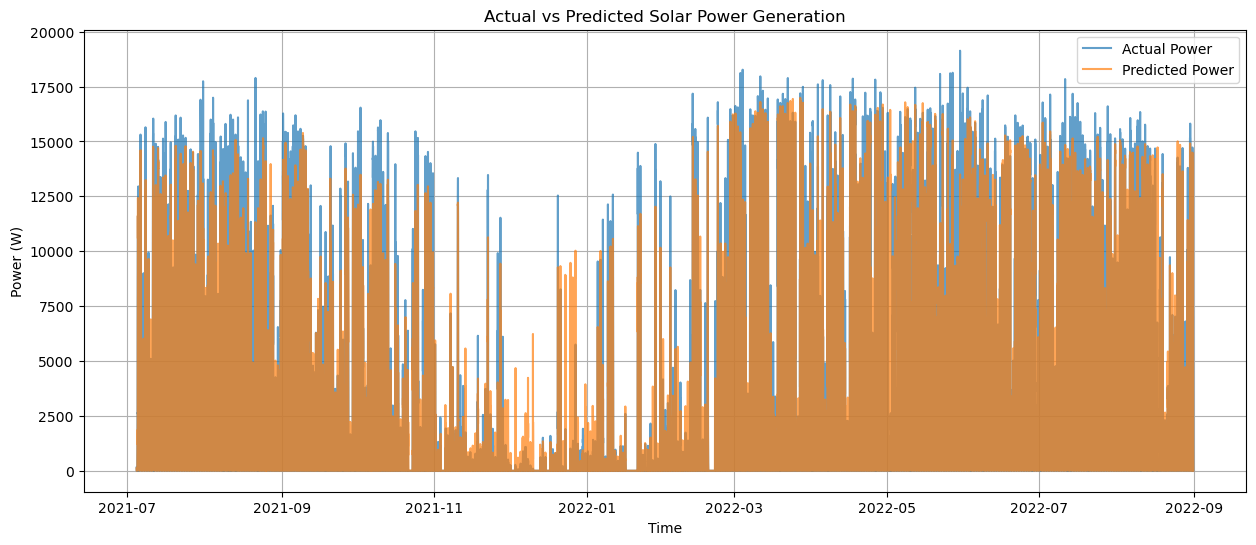

In [52]:
plt.figure(figsize=(15, 6))

plt.plot(
    residual_df["Time"],
    residual_df["Actual_Power"],
    label="Actual Power",
    alpha=0.7
)

plt.plot(
    residual_df["Time"],
    residual_df["Predicted_Power"],
    label="Predicted Power",
    alpha=0.7
)

plt.title("Actual vs Predicted Solar Power Generation")
plt.xlabel("Time")
plt.ylabel("Power (W)")

plt.legend()
plt.grid(True)

plt.show()

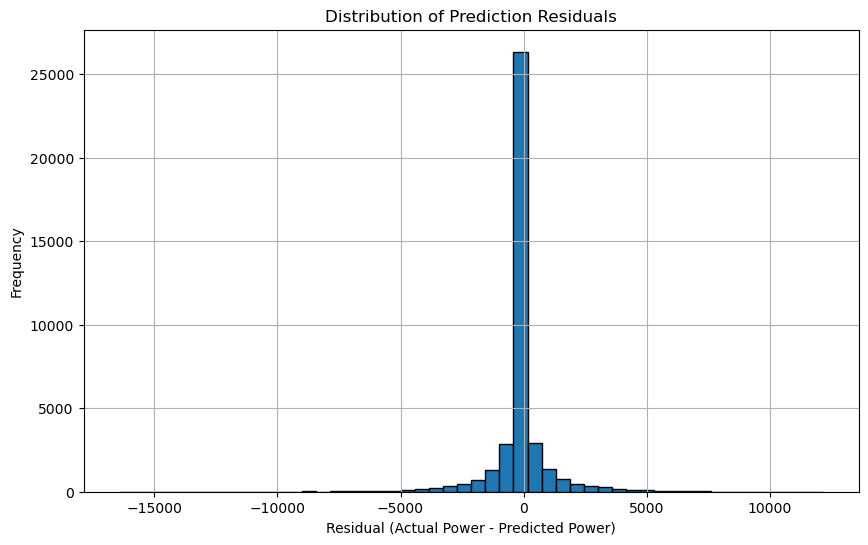

In [53]:
plt.figure(figsize=(10, 6))

plt.hist(residual_df["Residual"], bins=50, edgecolor="black")

plt.title("Distribution of Prediction Residuals")
plt.xlabel("Residual (Actual Power - Predicted Power)")
plt.ylabel("Frequency")

plt.grid(True)
plt.show()

In [54]:
residual_df["Residual"].describe()

count    39356.000000
mean       -86.800524
std       1330.339338
min     -16437.032000
25%       -113.290000
50%          0.000000
75%          0.000000
max      12174.680000
Name: Residual, dtype: float64

In [56]:
# identify high deviation periods 

# Calculate the 95th percentile threshold
threshold = residual_df["Absolute_Residual"].quantile(0.95)

print("95th Percentile Deviation Threshold:", threshold, "W")
# This means any test observation with an absolute residual greater than 2770.72 W
# will be marked as a high-deviation period.

95th Percentile Deviation Threshold: 2770.7193333333335 W


In [58]:
# Extract High-Deviation Observations
# Filter observations with high deviations
high_deviations = residual_df[
    residual_df["Absolute_Residual"] > threshold
]

print("Total High-Deviation Observations:", len(high_deviations))

print("\nFirst 10 High-Deviation Observations:")
high_deviations.head(10)


Total High-Deviation Observations: 1968

First 10 High-Deviation Observations:


,Time,Actual_Power,Predicted_Power,Residual,Absolute_Residual
157470,2021-07-05 07:30:00,10492,7429.36,3062.64,3062.64
157472,2021-07-05 08:00:00,7716,11260.80,-3544.80,3544.80
157477,2021-07-05 09:15:00,0,11757.36,-11757.36,11757.36
157478,2021-07-05 09:30:00,5120,11425.92,-6305.92,6305.92
157481,2021-07-05 10:15:00,8376,11304.20,-2928.20,2928.20
157484,2021-07-05 11:00:00,11512,8300.20,3211.80,3211.80
157488,2021-07-05 12:00:00,12004,9105.20,2898.80,2898.80
157489,2021-07-05 12:15:00,12952,7100.28,5851.72,5851.72
157491,2021-07-05 12:45:00,5464,2333.84,3130.16,3130.16
157585,2021-07-06 12:15:00,8104,13004.68,-4900.68,4900.68


In [60]:
# Analyze Deviations by Hour of Day ⏰

# Extract hour from timestamps
high_deviations["Hour"] = high_deviations["Time"].dt.hour

# Count high deviations by hour
hourly_deviations = high_deviations["Hour"].value_counts().sort_index()

print(hourly_deviations)

# High deviations are concentrated during 8 AM–1 PM.
# The maximum occurs at 10 AM with 345 observations.
# Deviations become much less frequent after 2 PM.
# There are almost no high deviations at 4 PM and beyond in this result.

Hour
6      18
7     101
8     238
9     307
10    345
11    316
12    281
13    187
14    130
15     43
16      2
Name: count, dtype: int64


C:\Users\Jamaal Ur Rahman\AppData\Local\Temp\ipykernel_11272\2133681745.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  high_deviations["Hour"] = high_deviations["Time"].dt.hour


In [61]:
# Analyze deviations by Weather conditions

# Add weather type from the original test dataset
high_deviations["Weather_Type"] = df.loc[
    high_deviations.index, "weather_type"
]

# Count high deviations by weather type
weather_deviations = high_deviations["Weather_Type"].value_counts().sort_index()

print(weather_deviations)

Weather_Type
1    107
2    471
3    464
4    648
5    278
Name: count, dtype: int64


C:\Users\Jamaal Ur Rahman\AppData\Local\Temp\ipykernel_11272\3296528121.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  high_deviations["Weather_Type"] = df.loc[


In [62]:
# Analyze deviations by Month

# Extract month from timestamp
high_deviations["Month"] = high_deviations["Time"].dt.month

# Count high deviations by month
monthly_deviations = high_deviations["Month"].value_counts().sort_index()

print(monthly_deviations)

Month
1      86
2      72
3      68
4     183
5     228
6     148
7     412
8     408
9      92
10    157
11     39
12     75
Name: count, dtype: int64


C:\Users\Jamaal Ur Rahman\AppData\Local\Temp\ipykernel_11272\723913870.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  high_deviations["Month"] = high_deviations["Time"].dt.month


In [63]:
# Analyze the Actual vs Predicted Difference by Weather Type 

# Add weather type to the full residual dataframe
residual_df["Weather_Type"] = df.loc[residual_df.index, "weather_type"]

# Calculate average absolute residual by weather type
weather_error_analysis = residual_df.groupby("Weather_Type")[
    "Absolute_Residual"
].mean()

print(weather_error_analysis)

Weather_Type
1    321.151966
2    653.930030
3    644.932956
4    507.282356
5    586.681730
Name: Absolute_Residual, dtype: float64


In [64]:
# Analyze Deviations by GHI 

# Divide GHI into ranges
residual_df["GHI_Range"] = pd.cut(
    df.loc[residual_df.index, "GHI"],
    bins=[-1, 100, 300, 600, 900, float("inf")],
    labels=["0-100", "100-300", "300-600", "600-900", "900+"]
)

# Calculate average absolute residual for each GHI range
ghi_error_analysis = residual_df.groupby(
    "GHI_Range", observed=False
)["Absolute_Residual"].mean()

print(ghi_error_analysis)

GHI_Range
0-100       338.975809
100-300    1750.189983
300-600            NaN
600-900            NaN
900+               NaN
Name: Absolute_Residual, dtype: float64


In [65]:
df.loc[residual_df.index, "GHI"].describe()

count    39356.000000
mean        35.367288
std         53.853070
min          0.000000
25%          0.000000
50%          3.600000
75%         55.400000
max        229.200000
Name: GHI, dtype: float64

In [66]:
df.loc[residual_df.index, "GHI"].max()

229.2

In [69]:
# Correct the GHI Analysis
residual_df["GHI_Range"] = pd.cut(
    df.loc[residual_df.index, "GHI"],
    bins=[-1, 5, 25, 50, 100, 300],
    labels=["0-5", "5-25", "25-50", "50-100", "100-300"]
)

ghi_error_analysis = residual_df.groupby(
    "GHI_Range", observed=False
)["Absolute_Residual"].mean()

print(ghi_error_analysis) 

# Higher irradiance levels correspond to higher solar generation, where changes in
# environmental conditions can lead to larger absolute prediction errors.

GHI_Range
0-5          11.065966
5-25        346.798550
25-50       886.605291
50-100     1362.235531
100-300    1750.189983
Name: Absolute_Residual, dtype: float64


In [70]:
high_deviation_percentage = (
    len(high_deviations) / len(residual_df)
) * 100

print("High-Deviation Percentage:", high_deviation_percentage, "%")

High-Deviation Percentage: 5.0005081817257855 %


In [71]:
# final deviation summary

# | Metric | Result |
# |---|---:|
# | Total test observations | 39,356 |
# | High-deviation observations | 1,968 |
# | Deviation threshold (95th percentile) | 2,770.72 W |
# | High-deviation percentage | 5.0005% |
# | Model R² score | 89.86% |
# | Random Forest MAE | 545.98 W |
# | Random Forest RMSE | 1,333.15 W |

# We used the 95th percentile of absolute residuals as the cutoff. 
#     Therefore, the top ~5% of observations are flagged for investigation.
#     The slight difference from exactly 5% is due to ties and the strict > threshold.

In [73]:
# Model Serialization using Joblib (Deployment)

import joblib
joblib.dump(rf_model, "solar_power_model.pkl")

['solar_power_model.pkl']

In [74]:
loaded_model = joblib.load("solar_power_model.pkl")

print("Model loaded successfully!")
print(type(loaded_model))

Model loaded successfully!
<class 'sklearn.ensemble._forest.RandomForestRegressor'>


# Preparing the Deployment Project


In [75]:
# Save the feature names
joblib.dump(X_train.columns.tolist(), "feature_names.pkl")

['feature_names.pkl']